# Analyzing the 6 versus 7 day work week using Chick-Fil-A as a case study

Imports and Settings

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import requests 
from io import StringIO
import numpy as np
from scipy import stats, optimize

In [2]:
focusrestaurant = "Chick-Fil-A"

Getting the Data

Sources: https://finance.yahoo.com/small-business/articles/qsr-50-2026-top-50-121001353.html?guccounter=1

In [3]:
QSR_2025 = pd.DataFrame([
    # chain, category, US sales ($M), average sales per unit ($K), total units, QSR estimate?
    ("McDonald's", "Burger", 55061, 4088, 13706, False),
    ("Starbucks", "Snack", 30250, 1800, 16860, True),
    ("Chick-fil-A", "Chicken", 23918, 7700, 3287, True),
    ("Taco Bell", "Global", 17247, 2216, 7784, False),
    ("Dunkin'", "Snack", 13106, 1400, 9999, False),
    ("Wendy's", "Burger", 11898, 2001, 5969, False),
    ("Chipotle", "Global", 11679, 3104, 3938, False),
    ("Burger King", "Burger", 11074, 1660, 6649, False),
    ("Domino's", "Pizza", 9953, 1385, 7186, False),
    ("Subway", "Sandwich", 9200, 490, 18773, True),
    ("Panda Express", "Global", 6408, 2646, 2607, False),
    ("Panera", "Sandwich", 5894, 2611, 2214, True),
    ("Popeyes", "Chicken", 5698, 1800, 3196, False),
    ("Raising Cane's", "Chicken", 5487, 6580, 913, False),
    ("Wingstop", "Chicken", 5343, 2000, 2586, False),
    ("Sonic Drive-In", "Burger", 5242, 1500, 3412, False),
    ("Pizza Hut", "Pizza", 5094, 808, 6307, False),
    ("Dairy Queen", "Burger", 5013, 1218, 4115, False),
    ("KFC", "Chicken", 4682, 1329, 3523, False),
    ("Whataburger", "Burger", 4311, 3914, 1161, False),
    ("Arby's", "Sandwich", 4239, 1300, 3265, False),
    ("Jersey Mike's", "Sandwich", 4217, 1360, 3227, False),
    ("Jack in the Box", "Burger", 4209, 1970, 2131, False),
    ("Culver's", "Burger", 4200, 4040, 1041, False),
    ("Papa Johns", "Pizza", 3702, 1124, 3294, True),
    ("Little Caesars", "Pizza", 3700, 950, 4374, True),
    ("Zaxbys", "Chicken", 2764, 2768, 1005, False),
    ("Jimmy John's", "Sandwich", 2737, 1000, 2777, False),
    ("In-N-Out", "Burger", 2600, 6032, 431, True),
    ("Five Guys", "Burger", 2313, 1531, 1511, False),
    ("Dutch Bros", "Snack", 2224, 2115, 1136, False),
    ("Hardee's", "Burger", 2027, 1344, 1492, False),
    ("Bojangles", "Chicken", 1948, 2156, 867, False),
    ("Shake Shack", "Burger", 1541, 4048, 420, True),
    ("Tropical Smoothie Cafe", "Snack", 1513, 978, 1659, False),
    ("Crumbl", "Snack", 1483, 1139, 1101, True),
    ("Carl's Jr.", "Burger", 1426, 1422, 992, False),
    ("QDOBA", "Global", 1268, 1700, 827, False),
    ("Firehouse Subs", "Sandwich", 1209, 960, 1276, False),
    ("7 Brew", "Snack", 1200, 2600, 602, False),
    ("CAVA", "Global", 1169, 2934, 439, False),
    ("El Pollo Loco", "Chicken", 1125, 2300, 503, False),
    ("Marco's Pizza", "Pizza", 1094, 832, 1184, False),
    ("Freddy's", "Burger", 1040, 1901, 580, False),
    ("McAlister's", "Sandwich", 1029, 1868, 572, False),
    ("Nothing Bundt Cakes", "Snack", 982, 1261, 779, True),
    ("Dave's Hot Chicken", "Chicken", 966, 2718, 358, True),
    ("Del Taco", "Global", 919, 1600, 576, False),
    ("Church's Chicken", "Chicken", 862, 1138, 770, False),
    ("Scooter's Coffee", "Snack", 859, 999, 906, False),
], columns=["chain", "category", "sales_musd", "auv_kusd", "units", "estimate"]).set_index("chain")
QSR_2025.head(5)

,category,sales_musd,auv_kusd,units,estimate
chain,,,,,
McDonald's,Burger,55061,4088,13706,False
Starbucks,Snack,30250,1800,16860,True
Chick-fil-A,Chicken,23918,7700,3287,True
Taco Bell,Global,17247,2216,7784,False
Dunkin',Snack,13106,1400,9999,False


Plotting the Average Yearly Sales per Restaurant for each Franchise

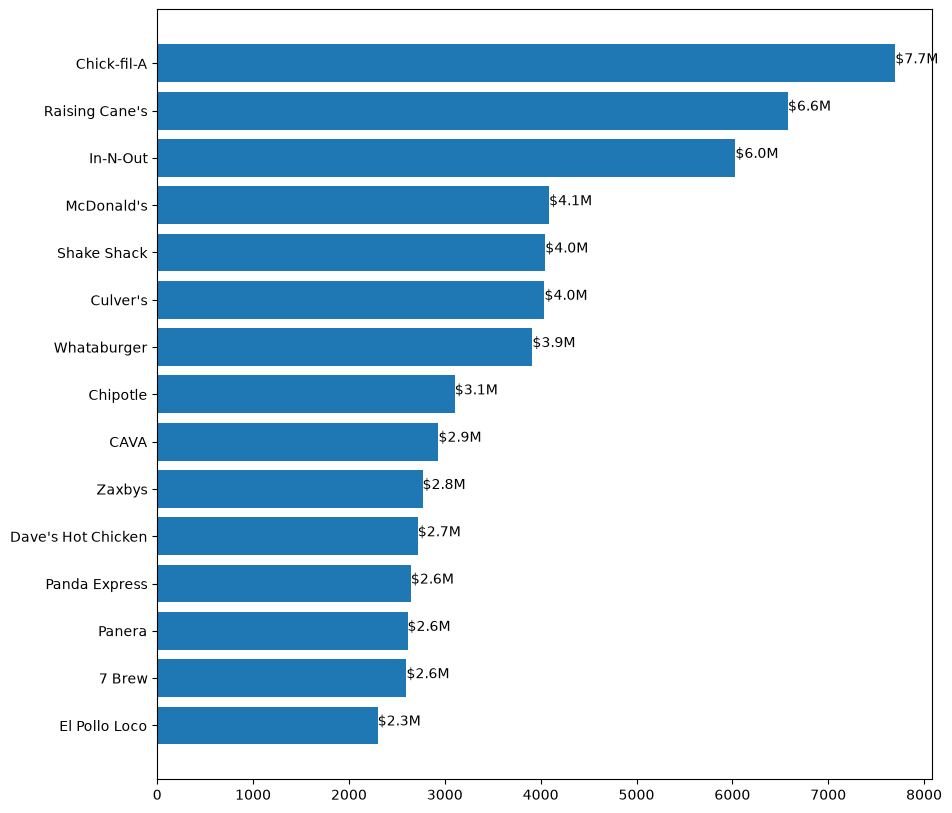

In [4]:
topx = 15
sortedQSR = QSR_2025.sort_values(by = "auv_kusd", ascending=False)
sortedQSR = sortedQSR.head(topx)
sortedQSR = sortedQSR.iloc[::-1]
fig, ax = plt.subplots(figsize = (10, 10))
bars = ax.barh(sortedQSR.index, sortedQSR["auv_kusd"])
for bar in bars:
    barwidth = bar.get_width()
    ax.text(barwidth, bar.get_y() + bar.get_height()/2, f"${barwidth/1000:.1f}M")
plt.show()